# 16 — Fusión online (C1)

**Pregunta.** ¿Una media de las probabilidades de crisis de todos los detectores no supervisados, con pesos que se
actualizan cada mes según lo que cada uno acertó en las crisis **ya terminadas**, mejora al mejor detector solo?
Es la agregación de modelos de crisis de Fouliard et al. (2020), adaptada a la vara del proyecto.

Todo está **pre-registrado** en el [ADR-011](../../docs/decisions/ADR-011-preregistro-fusiones.md) (§4 la construcción,
§5 la vara, §6.2 el criterio, §6.3 lo que se reporta sin peso). Se compara la fusión online **O** con:

- **M**, la media simple (los mismos detectores con pesos iguales: η = 0);
- **V**, la votación por mayoría de todos;
- **F\***, la mejor fusión fija, elegida en la primera mitad ([notebook 15](15_fusiones_fijas.ipynb));
- **I\***, el mejor detector individual del ranking ([notebook 14](14_comparativa.ipynb)).

Este notebook **no calcula nada caro**: lee `results/fusion/online/` (lo deja `python -m regimenes.fusion.online
ejecutar`, con las 5.000 réplicas del MCS) y dibuja con `regimenes.fusion.figuras_online`. **Todas las cifras salen
de celdas.**

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

from regimenes.fusion import online as on
from regimenes.fusion import figuras_online as fo

RESUMEN = on.leer_resumen()
HECHOS = fo.hechos()
print(f"Veredicto §6.2: «{RESUMEN['veredicto']}» · cumple por pista {RESUMEN['cumple_por_pista']} · "
      f"los pesos aprenden: {RESUMEN['los_pesos_aprenden']} · F*: {RESUMEN['F*']}")

Veredicto §6.2: «indicio» · cumple por pista {'A': True, 'B': False} · los pesos aprenden: False · F*: {'A': 'AND_D01+D10-P', 'B': 'VOTO_3de5'}


## 0. Resumen

Score de detección (F1 entre la precisión diaria y el recall por evento,
[ADR-003](../../docs/decisions/ADR-003-causalidad-calendario-estado-ranking.md)) de O y de sus cuatro comparadores, en
**todo el OOS** (barra llena) y en la **segunda mitad H2** (rayada). Las líneas verticales son los dos umbrales del
criterio: I\* en todo el OOS para (i) y el mejor individual de la primera mitad (I\*\_H1) en H2 para (iii). ● / ○ =
dentro / fuera del MCS-O al 10 %.

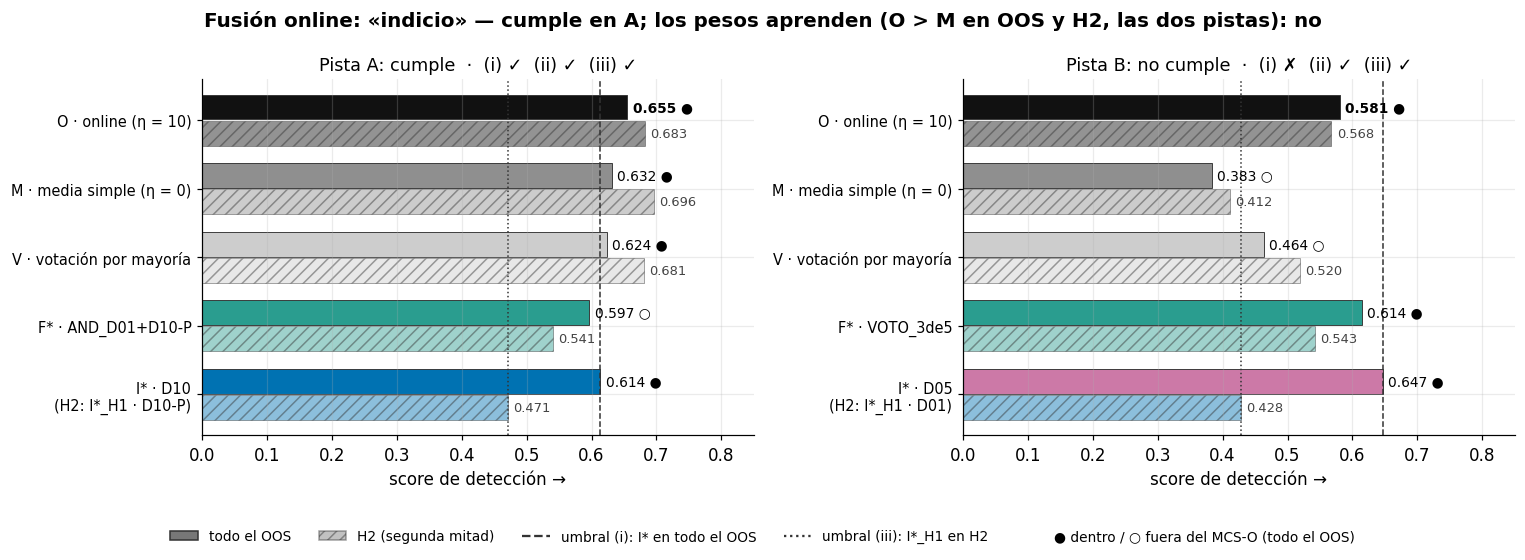

In [2]:
fig = fo.figura_resumen()
plt.show()

In [3]:
display(Markdown('\n'.join(f'{i}. {c}' for i, c in enumerate(fo.conclusiones(HECHOS), 1))))

1. **Veredicto del §6.2: «indicio».** En A, O cumple los tres criterios: 0.655 frente a 0.614 de D10 en todo el OOS, dentro del MCS-O (p = 0.91) y 0.683 frente a 0.471 de D10-P en H2. En B falla (i): 0.581 frente a 0.647 de D05 (sí cumple (ii), (iii)).
2. **Los pesos aprenden: no** (hace falta O > M en las dos pistas y en los dos tramos). A: O 0.655 vs M 0.632 en todo el OOS y 0.683 vs 0.696 en H2; B: O 0.581 vs M 0.383 en todo el OOS y 0.568 vs 0.412 en H2. En A la media simple, con pesos iguales, iguala o supera a O en algún tramo, así que allí la ventaja de O no se puede atribuir a aprender los pesos; en B, en cambio, O supera a M en los dos tramos.
3. **Frente a la mejor fusión fija (F\*, todo el OOS):** en A gana O (0.655 O vs 0.597 F* = AND_D01+D10-P); en B gana F* (0.581 O vs 0.614 F* = VOTO_3de5).
4. **Tasa de aprendizaje (sin peso):** en A gana η = 5 en H1, que en H2 da 0.688 frente a 0.683 de η = 10; en B gana en H1 el mismo η = 10 que se fijó a priori.
5. **Los pesos no se quedan con un solo detector:** en A, n efectivo medio 8.9 de 15 y al final D06 22%, D05 19%, D01 13%; en B, n efectivo medio 7.4 de 17 y al final D05 25%, D06 23%, D10 16%.

## 1. La idea en una figura

- **Combinación.** Cada día, `p̄_t = Σ_i w_i · p_crisis_i,t` sobre **todos** los candidatos de la pista (sin elegir),
  y crisis si `p̄_t ≥ 0,50`, sin persistencia añadida.
- **Pérdida.** `L_i(τ) = 1 − J` de Youden con las crisis equiponderadas: la **misma** pérdida con la que el MCS juzga
  el resultado. Se mide sobre la señal binaria de cada detector, solo con los días hasta τ y con las crisis **ya
  terminadas** (suelo ≤ τ). Una crisis en curso cuenta como calma: penaliza a quien la marca mientras dura, como le
  pasaría a alguien en tiempo real. Se recalcula entera cada mes.
- **Pesos.** `w_i ∝ exp(−η · L_i)` (pesos de *Hedge* con la pérdida media), con η = 10 fijado a priori por la escala
  de las pérdidas (ADR-011 §4.4).
- **Calendario.** Se calculan al cierre del último día OOS de cada mes (τ) y rigen **todo el mes siguiente**: nunca
  se usa un dato del mismo día. Hasta la primera crisis terminada con días OOS, pesos iguales.

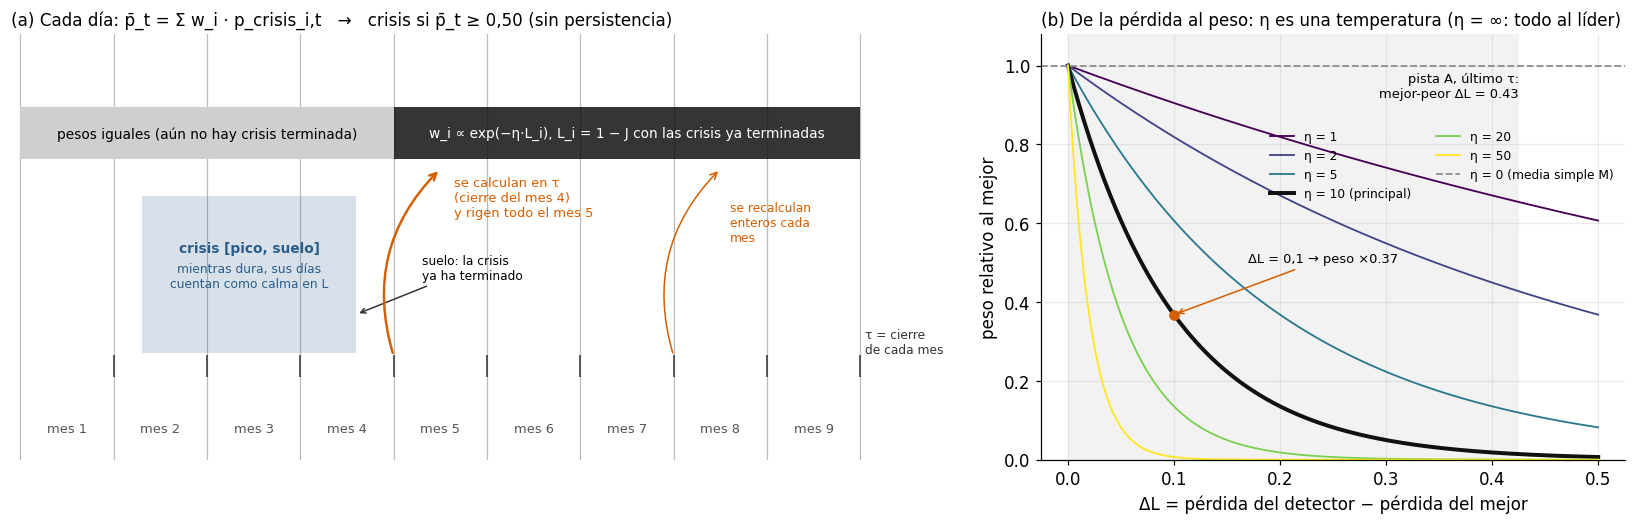

Pista A: 15 candidatos, 673 meses OOS; primeros pesos aprendidos en τ = 1970-05-29 (rigen desde 1970-06-01); 673 cierres de mes (τ) con pesos aprendidos.
Pista B: 17 candidatos, 194 meses OOS; primeros pesos aprendidos en τ = 2010-07-30 (rigen desde 2010-08-02); 191 cierres de mes (τ) con pesos aprendidos.


In [4]:
fig = fo.figura_mecanismo('A')
plt.show()
for p in fo.PISTAS:
    r = fo.resumen_pesos(p)
    print(f"Pista {p}: {r['n']} candidatos, {r['n_meses']} meses OOS; primeros pesos aprendidos en τ = {r['primer_tau']} "
          f"(rigen desde {r['primera_vigencia']}); {r['n_meses_aprendidos']} cierres de mes (τ) con pesos aprendidos.")

## 2. Cómo evolucionan los pesos

Área apilada de los pesos de O a lo largo del tiempo: cada franja es un detector, con el color de su familia (la
paleta del notebook 14) y rayada si es una variante del pool. Los triángulos marcan el suelo de cada crisis: a partir
del mes siguiente esa crisis entra en la pérdida. Abajo, el **número efectivo de detectores** `exp(entropía)`: vale
el total con pesos iguales y 1 si un solo detector lo decide todo.

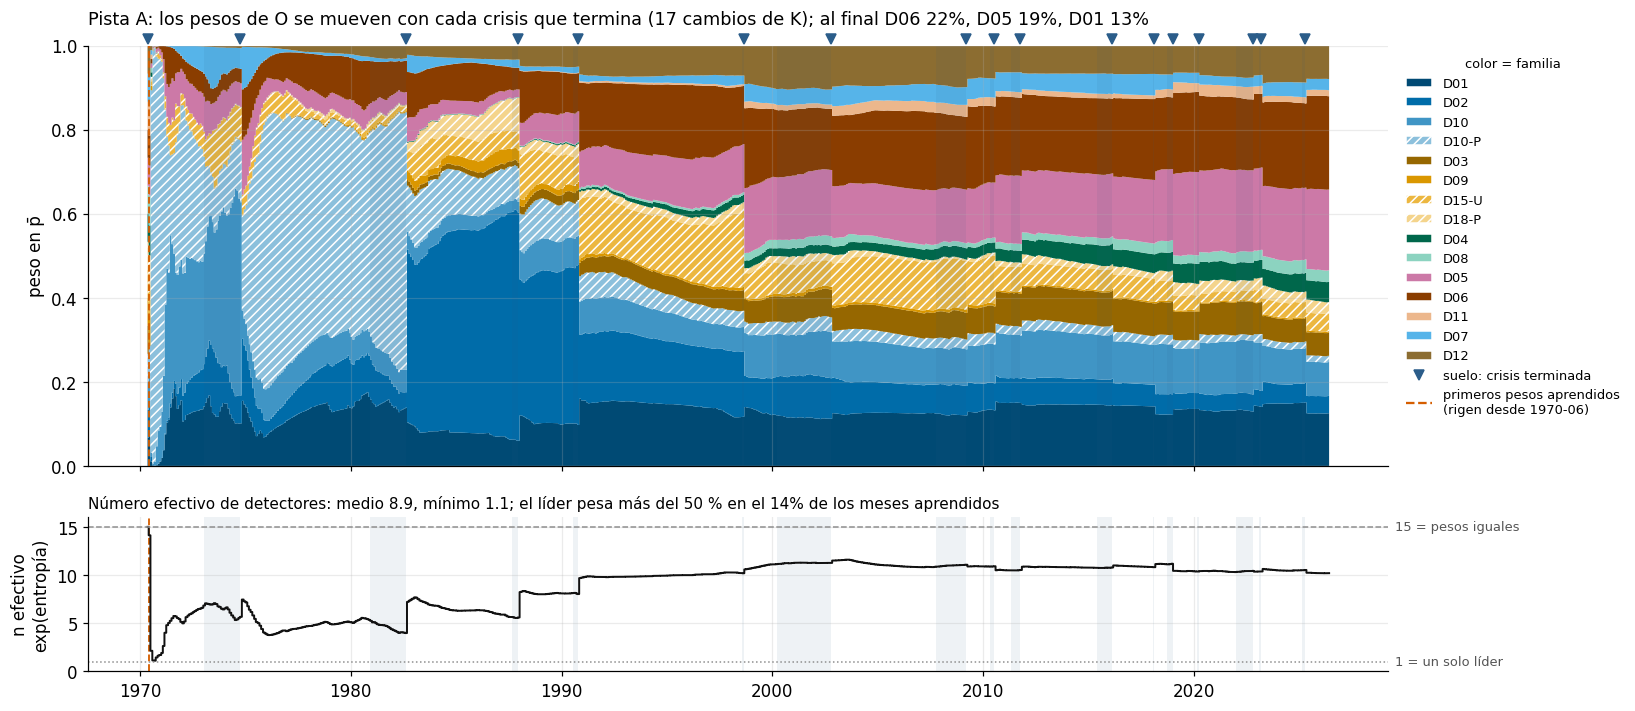

In [5]:
fig = fo.figura_pesos('A')
plt.show()

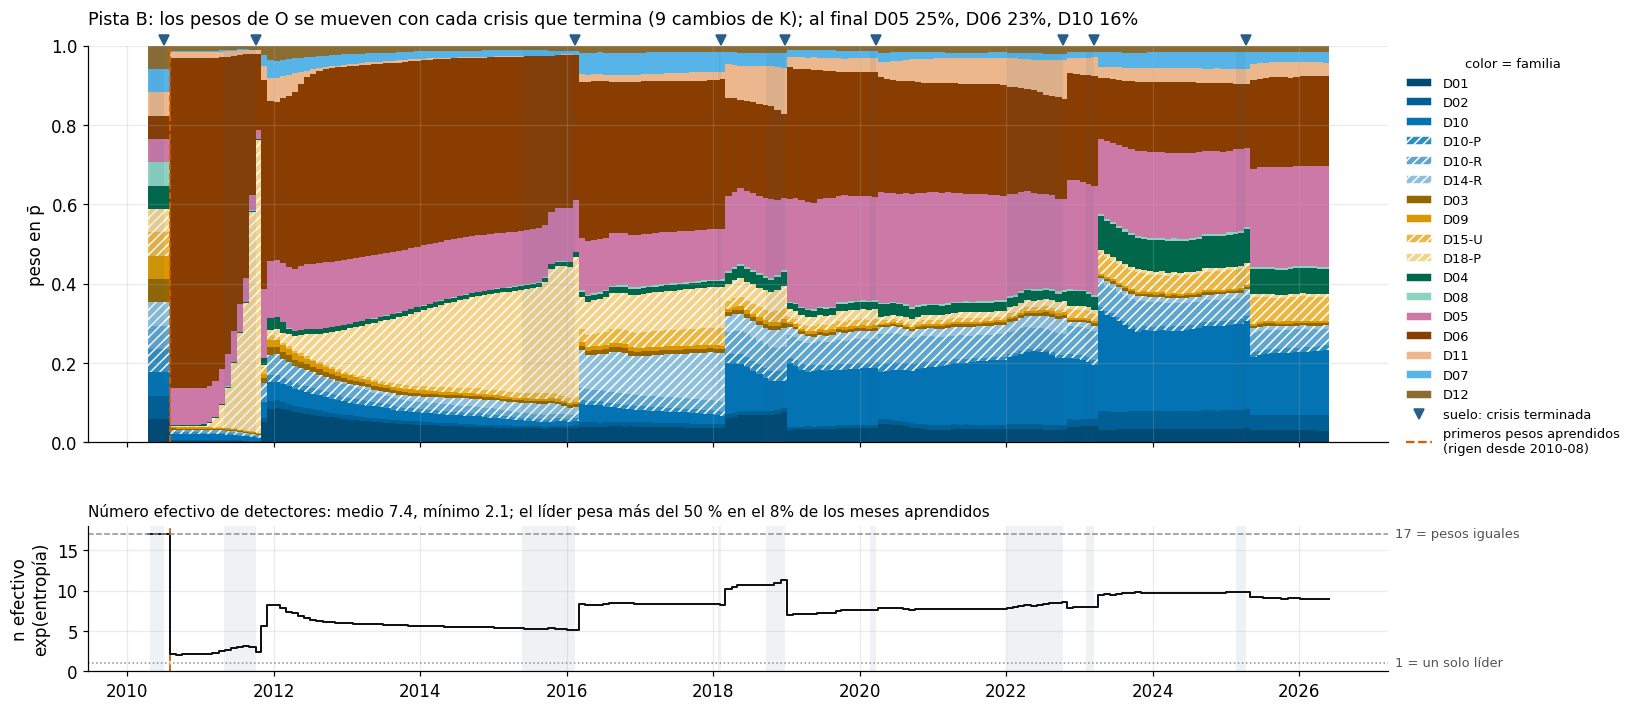

In [6]:
fig = fo.figura_pesos('B')
plt.show()

In [7]:
display(pd.DataFrame({p: on.pesos_finales(p, top=None).round(3) for p in fo.PISTAS}).fillna('—')
        .rename_axis('peso de O en el último τ'))

,A,B
peso de O en el último τ,,
D01,0.125,0.029
D02,0.041,0.040
D03,0.055,0.006
D04,0.048,0.063
D05,0.192,0.254
D06,0.223,0.228
D07,0.027,0.028
D08,0.028,0.006
D09,0.003,0.005


**Lectura.** Al principio los pesos saltan con cada crisis nueva, porque se aprenden con muy pocas (la primera de A
apenas tiene días OOS, ADR-011 §4.2) y un detector puede llevarse casi todo. Con el tiempo se estabilizan en una mezcla
amplia: ningún detector se queda con todo, y los que más pesan al final son los de menor pérdida 1 − J (los primeros
del MCS), que no siempre coinciden con el primero del ranking por score. O se parece más a una media de los buenos que
a seguir al líder.

## 3. p̄ y señal frente a las crisis

Arriba, `p̄` de O y de M y la `p_crisis` del mejor individual I\*; la franja azul es cada crisis `[pico, suelo]` y la
gris, las trampas (episodios que no son crisis). Abajo, la señal binaria de cada comparador; entre paréntesis, las
crisis detectadas (≥ 3 sesiones seguidas en crisis dentro de la ventana).

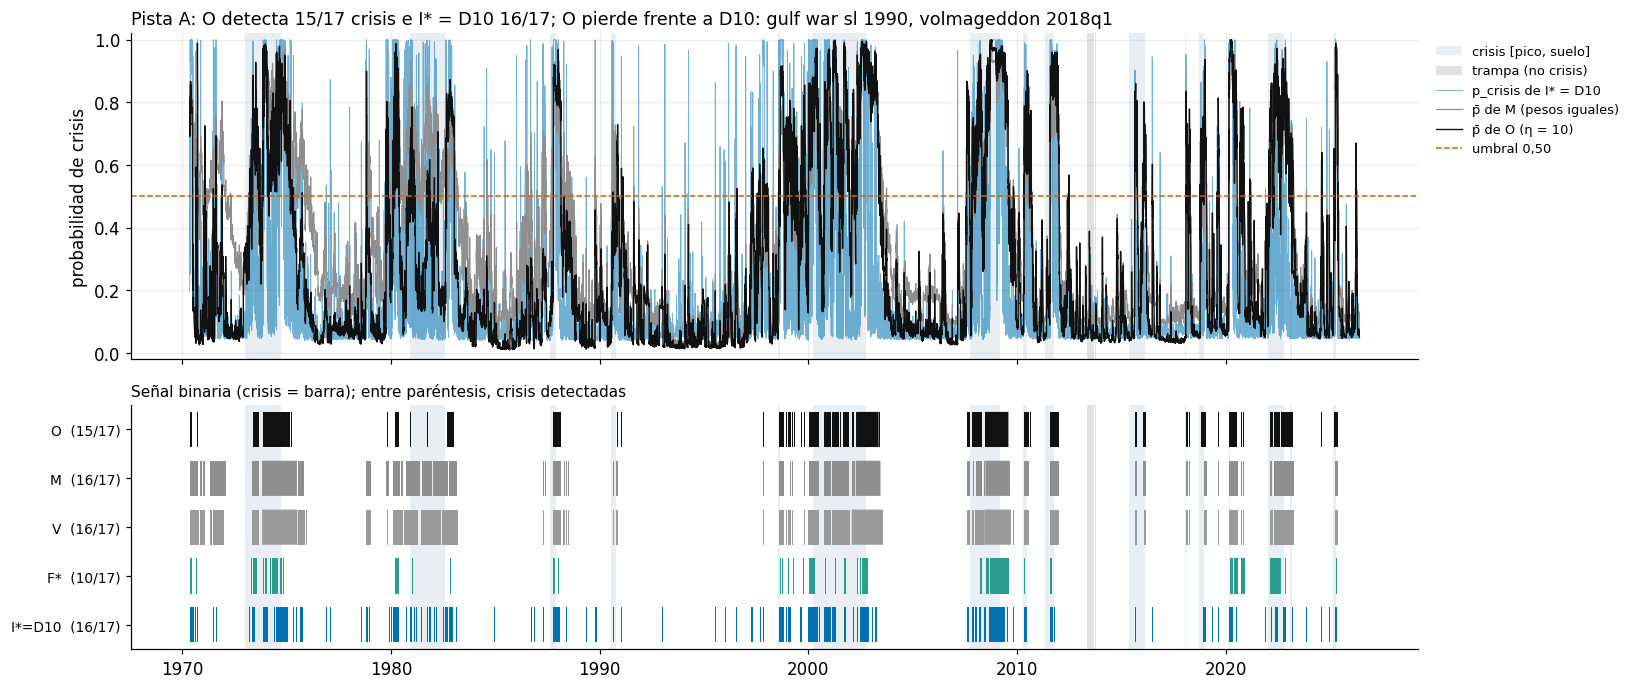

In [8]:
fig = fo.figura_cronograma('A')
plt.show()

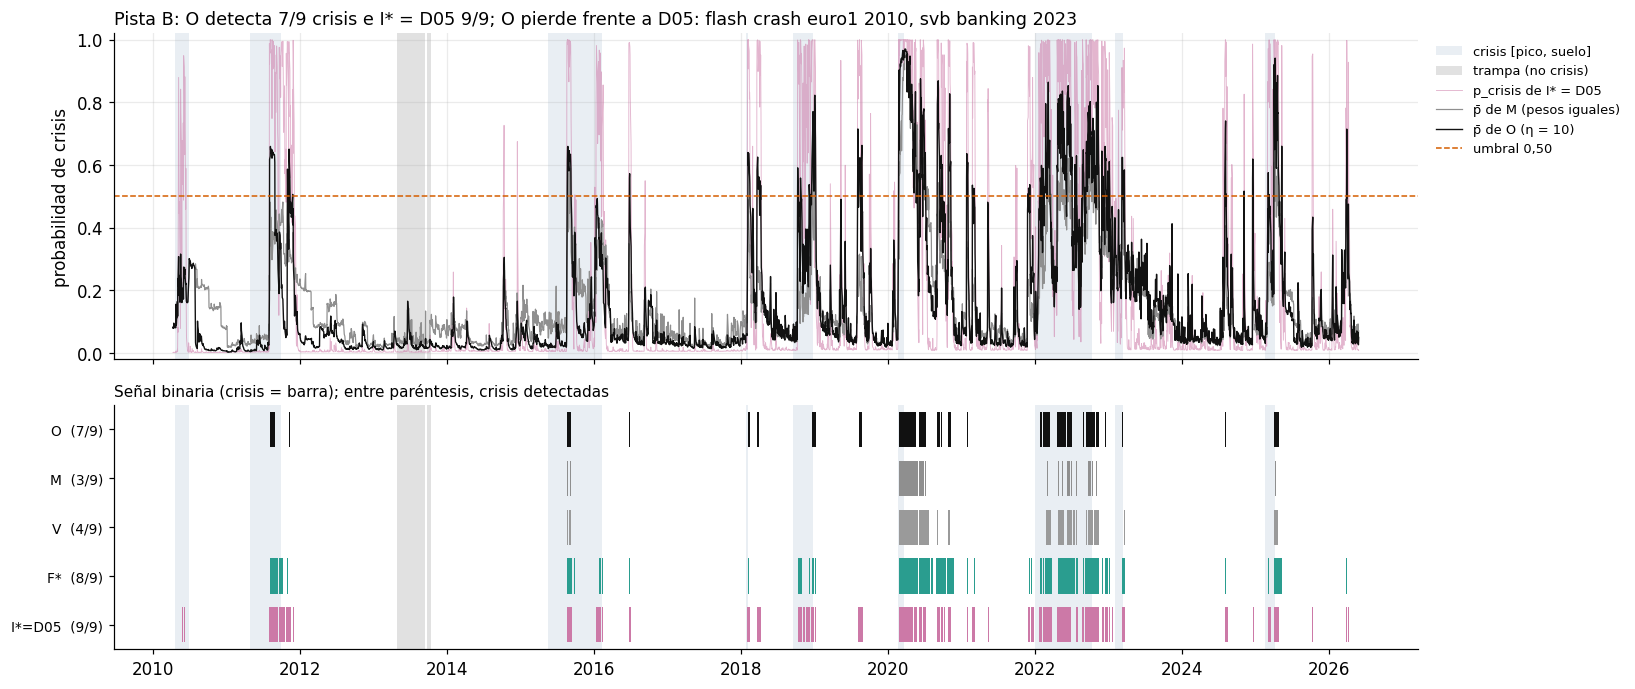

In [9]:
fig = fo.figura_cronograma('B')
plt.show()

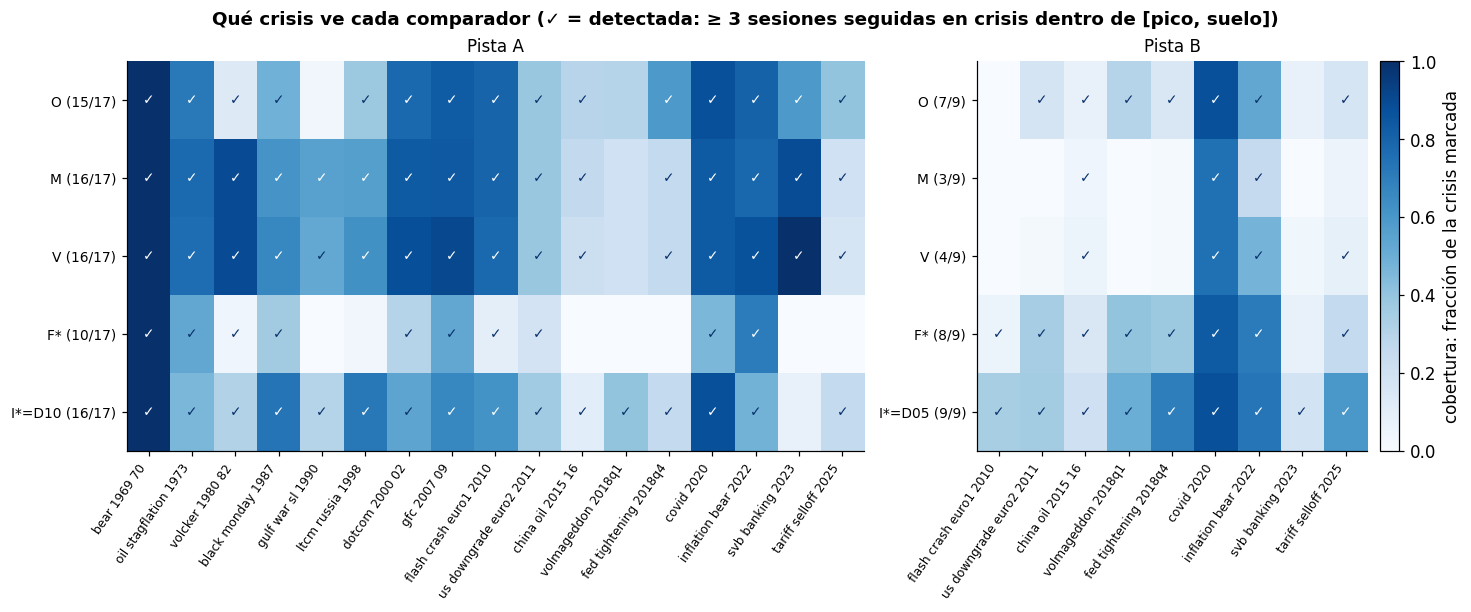

id_oos  score_oos  recall_oos  precision_oos  nivel_oos
  comparador                                                                
A O                       O      0.655       0.882          0.521          0
  M                       M      0.632       0.941          0.476          0
  V                       V      0.624       0.941          0.466          0
  F*          AND_D01+D10-P      0.597       0.588          0.605          0
  I*                    D10      0.614       0.941          0.455          0
B O                       O      0.581       0.778          0.464          0
  M                       M      0.383       0.333          0.451          0
  V                       V      0.464       0.444          0.485          0
  F*              VOTO_3de5      0.614       0.889          0.469          0
  I*                    D05      0.647       1.000          0.478          0

In [10]:
fig = fo.figura_crisis()
plt.show()
display(pd.concat({p: fo.tabla_comparadores(p)[['id_oos', 'score_oos', 'recall_oos', 'precision_oos', 'nivel_oos']]
                   for p in fo.PISTAS}).round(3))

**Lectura.** En A, O pierde algo de recall frente a M, V e I\* pero gana precisión: marca menos días fuera de las
crisis y por eso sube el score. En B, M y V casi nunca cruzan el umbral (con tantos detectores, la mayoría rara vez
coincide) y O, al concentrar el peso en los buenos, recupera crisis; aun así se queda por debajo de I\*.

## 4. Criterio del §6.2 y MCS-O

**La fusión online aporta** si, en **cada una de las dos pistas**, O cumple a la vez:

- **(i)** nivel 0 y score en todo el OOS **estrictamente mayor** que el de I\* (puesto 1 del ranking v3 ampliado);
- **(ii)** está dentro del **MCS-O** al 10 % de todo el OOS (individuales, 5 baselines, F\*, V, M y O; bloque fijo y
  5.000 réplicas, ADR-011 §5.1);
- **(iii)** en H2, nivel 0 y score estrictamente mayor que el de I\*\_H1 (el mejor de la primera mitad).

Si cumple en una sola pista es un **indicio**. Sin redondeo ni margen: un empate no cumple.

In [11]:
display(fo.tabla_criterio().round(3))
print(f"Veredicto: «{RESUMEN['veredicto']}»")

O  referencia            ref cumple
pista criterio                                                                              
A     (i) O > I* en todo el OOS, nivel 0             0.655       0.614       I* = D10      ✓
      (ii) O dentro del MCS-O al 10 % (todo el OOS)  0.912       0.100      p_MCS > α      ✓
      (iii) O > I*_H1 en H2, nivel 0                 0.683       0.471  I*_H1 = D10-P      ✓
      → la pista cumple (i)+(ii)+(iii)                 NaN         NaN                     ✓
B     (i) O > I* en todo el OOS, nivel 0             0.581       0.647       I* = D05      ✗
      (ii) O dentro del MCS-O al 10 % (todo el OOS)  0.347       0.100      p_MCS > α      ✓
      (iii) O > I*_H1 en H2, nivel 0                 0.568       0.428    I*_H1 = D01      ✓
      → la pista cumple (i)+(ii)+(iii)                 NaN         NaN                     ✗

Veredicto: «indicio»


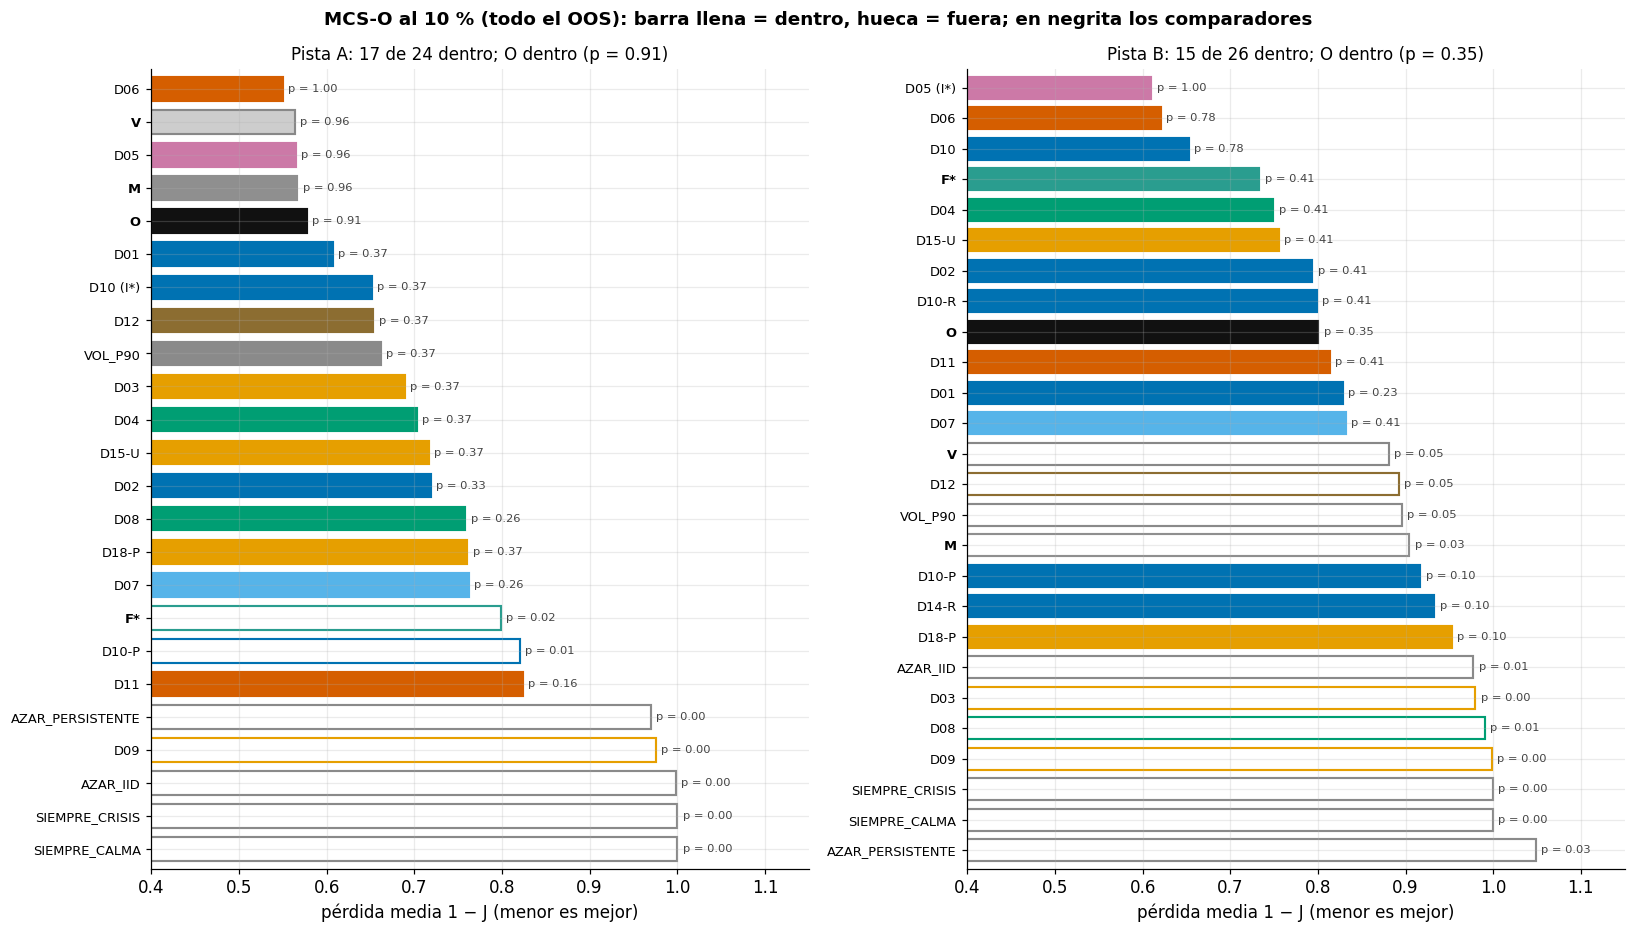

In [12]:
fig = fo.figura_mcs('oos')
plt.show()

In [13]:
# MCS-O en H2: sin peso (pocas crisis por mitad, sobre todo en B).
display(pd.DataFrame({p: on.leer_mcs(p, 'H2').loc[['O', 'M', 'V', 'F*'], 'incluido'] for p in fo.PISTAS})
        .rename_axis('dentro del MCS-O en H2'))

,A,B
dentro del MCS-O en H2,,
O,True,True
M,True,True
V,True,True
F*,False,True


**Veredicto secundario, «los pesos aprenden»:** O debe superar a M (la misma media con pesos iguales) en las dos pistas,
en todo el OOS **y** en H2. No cambia el veredicto principal; dice si lo que aporta O viene de aprender los pesos o de
promediar.

In [14]:
display(fo.tabla_aprenden().round(3))
print(f"Los pesos aprenden: {'sí' if RESUMEN['los_pesos_aprenden'] else 'no'}")

O      M  O − M O > M
pista tramo                           
A     oos    0.655  0.632  0.023     ✓
      H2     0.683  0.696 -0.014     ✗
B     oos    0.581  0.383  0.198     ✓
      H2     0.568  0.412  0.156     ✓

Los pesos aprenden: no


## 5. Tasa de aprendizaje

Sin peso en el veredicto (ADR-011 §4.4). η = 10 se fijó antes de calcular; como control se mira qué η de la rejilla
gana en H1 (orden del §5.2) y cómo rinde en H2. η = 0 es M y η = ∞ es *follow the leader*.

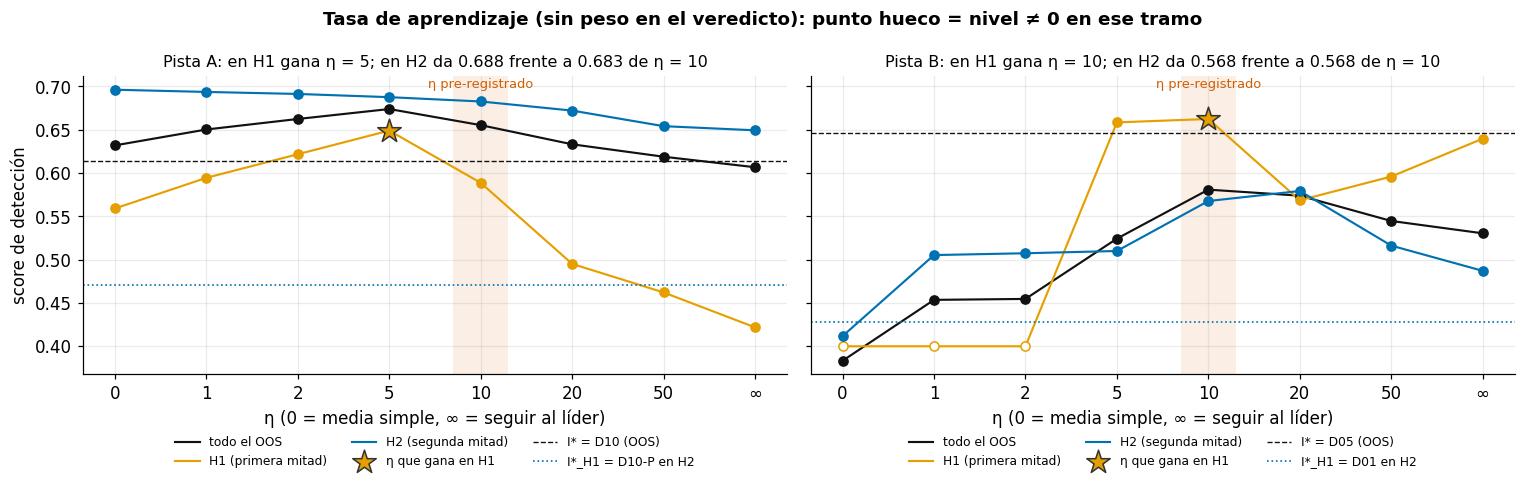

puesto_H1  nivel_oos  score_deteccion_oos  nivel_H1  score_deteccion_H1  nivel_H2  score_deteccion_H2
pista η                                                                                                        
A     0           5          0                0.632         0               0.559         0               0.696
      1           3          0                0.650         0               0.595         0               0.694
      2           2          0                0.662         0               0.622         0               0.691
      5           1          0                0.674         0               0.649         0               0.688
      10          4          0                0.655         0               0.589         0               0.683
      20          6          0                0.633         0               0.495         0               0.672
      50          7          0                0.619         0               0.462         0               0.654
      ∞           8          0                0.607         0               0.422         0               0.649
B     0           6          0                0.383         2               0.400         0               0.412
      1           7          0                0.454         2               0.400         0               0.505
      2           8          0                0.455         2               0.400         0               0.507
      5           2          0                0.524         0               0.659         0               0.510
      10          1          0                0.581         0               0.662         0               0.568
      20          5          0                0.574         0               0.569         0               0.579
      50          4          0                0.545         0               0.596         0               0.516
      ∞           3          0                0.530         0               0.640         0               0.487

In [15]:
fig = fo.figura_eta()
plt.show()
display(fo.tabla_eta().round(3))

**Lectura.** En todo el OOS el score tiene forma de campana: con η pequeño se diluyen los buenos y con η grande se
sigue a un líder que cambia con cada crisis. El η pre-registrado cae cerca del máximo, pero las curvas de H1 y H2 no
coinciden, sobre todo en B (pocas crisis): el η óptimo no es estable entre mitades.

## 6. Sensibilidades y utilidad operativa (sin peso)

Las cuatro sensibilidades del ADR-011 §6.3, todas con η = 10: entrada **binaria** en vez de `p_crisis`; **63 sesiones**
de retraso en reconocer que una crisis ha terminado; pesos iguales hasta que las crisis terminadas sumen **21 días**
OOS; y sacar de la pérdida los días de crisis **aún sin terminar** (usa la fecha de inicio, que es futura). La última
fila, binaria con η = 0, es V y sirve de comprobación.

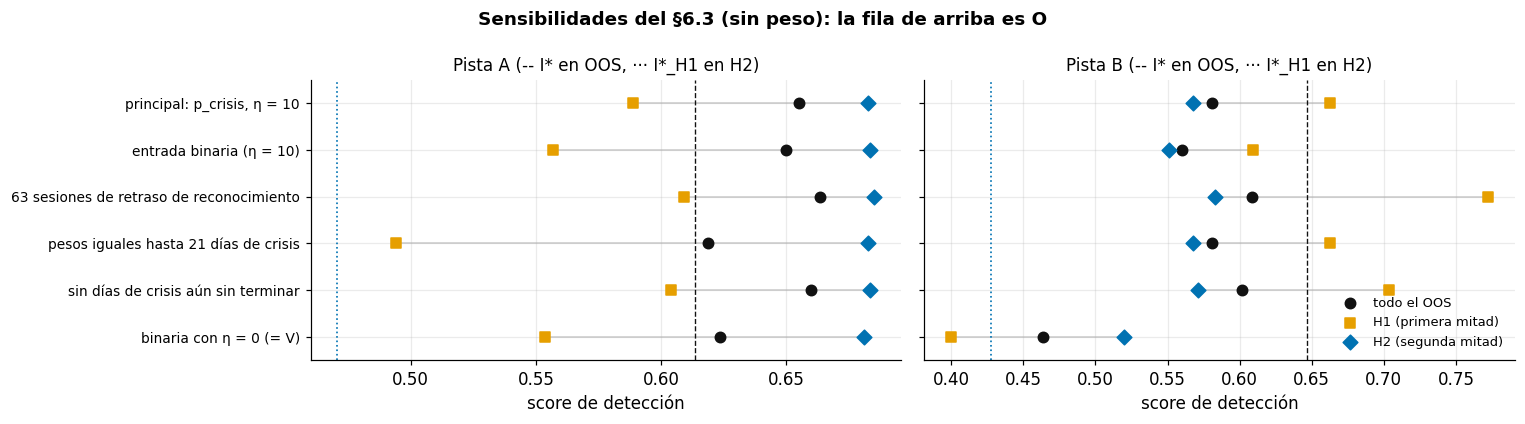

oos     H1     H2  Δ oos vs principal  Δ H2 vs principal
pista variante                                                                                            
A     principal: p_crisis, η = 10               0.655  0.589  0.683               0.000              0.000
      entrada binaria (η = 10)                  0.650  0.557  0.684              -0.005              0.001
      63 sesiones de retraso de reconocimiento  0.663  0.609  0.685               0.008              0.003
      pesos iguales hasta 21 días de crisis     0.619  0.494  0.683              -0.036             -0.000
      sin días de crisis aún sin terminar       0.660  0.604  0.684               0.005              0.001
      binaria con η = 0 (= V)                   0.624  0.554  0.681              -0.032             -0.001
B     principal: p_crisis, η = 10               0.581  0.662  0.568               0.000              0.000
      entrada binaria (η = 10)                  0.560  0.609  0.551              -0.021             -0.017
      63 sesiones de retraso de reconocimiento  0.609  0.772  0.583               0.028              0.015
      pesos iguales hasta 21 días de crisis     0.581  0.662  0.568               0.000              0.000
      sin días de crisis aún sin terminar       0.602  0.704  0.571               0.021              0.003
      binaria con η = 0 (= V)                   0.464  0.400  0.520              -0.117             -0.048

In [16]:
fig = fo.figura_sensibilidades()
plt.show()
display(fo.tabla_sensibilidades().round(3))

**Utilidad operativa** de los notebooks de fusión anteriores (cobertura media de las crisis, tasa de falsa alarma,
duración media de los episodios y utilidad), solo como lectura secundaria.

In [17]:
display(fo.tabla_utilidad().round(3))

mean_crisis_coverage  false_alarm_rate  mean_duration  operational_utility
pista tramo id                                                                                
A     oos   O                      0.552             0.479         27.179               -0.110
            M                      0.628             0.524         23.093               -0.112
            V                      0.645             0.534         27.390               -0.071
            F*                     0.249             0.395         88.331               -0.202
            I*=D10                 0.481             0.545         23.954               -0.273
      H2    O                      0.585             0.456         21.879               -0.099
            M                      0.571             0.439         21.350               -0.101
            V                      0.593             0.458         26.369               -0.053
            F*                     0.193             0.411         72.856               -0.287
            I*=D10                 0.447             0.427         25.421               -0.175
B     oos   O                      0.261             0.536         30.985               -0.436
            M                      0.124             0.549         44.604               -0.536
            V                      0.160             0.515         66.541               -0.429
            F*                     0.357             0.531         43.645               -0.287
            I*=D05                 0.499             0.522         22.932               -0.240
      H2    O                      0.361             0.560         18.288               -0.470
            M                      0.214             0.576         23.882               -0.568
            V                      0.272             0.542         38.302               -0.397
            F*                     0.451             0.589         27.808               -0.316
            I*=D05                 0.617             0.551         15.736               -0.249

## 7. Conclusiones

In [18]:
display(Markdown('\n'.join(f'- {c}' for c in fo.conclusiones(HECHOS))))

- **Veredicto del §6.2: «indicio».** En A, O cumple los tres criterios: 0.655 frente a 0.614 de D10 en todo el OOS, dentro del MCS-O (p = 0.91) y 0.683 frente a 0.471 de D10-P en H2. En B falla (i): 0.581 frente a 0.647 de D05 (sí cumple (ii), (iii)).
- **Los pesos aprenden: no** (hace falta O > M en las dos pistas y en los dos tramos). A: O 0.655 vs M 0.632 en todo el OOS y 0.683 vs 0.696 en H2; B: O 0.581 vs M 0.383 en todo el OOS y 0.568 vs 0.412 en H2. En A la media simple, con pesos iguales, iguala o supera a O en algún tramo, así que allí la ventaja de O no se puede atribuir a aprender los pesos; en B, en cambio, O supera a M en los dos tramos.
- **Frente a la mejor fusión fija (F\*, todo el OOS):** en A gana O (0.655 O vs 0.597 F* = AND_D01+D10-P); en B gana F* (0.581 O vs 0.614 F* = VOTO_3de5).
- **Tasa de aprendizaje (sin peso):** en A gana η = 5 en H1, que en H2 da 0.688 frente a 0.683 de η = 10; en B gana en H1 el mismo η = 10 que se fijó a priori.
- **Los pesos no se quedan con un solo detector:** en A, n efectivo medio 8.9 de 15 y al final D06 22%, D05 19%, D01 13%; en B, n efectivo medio 7.4 de 17 y al final D05 25%, D06 23%, D10 16%.

**Qué significa para el TFM.**

- La fusión online pasa el criterio completo **solo en A**: es un **indicio**, no un aporte. En B no supera al mejor
  detector solo.
- **No se puede decir que los pesos aprendan.** En A la media simple de todos (M) queda muy cerca de O (algo por debajo
  en todo el OOS, algo por encima en la segunda mitad): allí lo que ayuda es promediar muchos detectores imperfectos,
  que sube la precisión. En B, en cambio, M casi nunca cruza el umbral y los pesos sí marcan la diferencia, pero O
  sigue por debajo del mejor detector solo.
- Los pesos aprendidos acaban favoreciendo a los detectores de menor pérdida, los mismos que ya encabezan el MCS de
  los individuales, sin quedarse con uno solo. Es coherente con el resto de la Fase 2: no aparece un detector oculto que la fusión descubra.

**Qué queda para la decisión final** ([notebook 21](21_decision_final.ipynb), no se hace ahora): elegir entre el mejor
individual, una media simple de detectores o la online, sabiendo que la online solo gana en A, donde apenas se
separa de la media simple (que en B, sin pesos, no sirve). Los resultados de esta fase los escribe el director en el §9 del
[ADR-011](../../docs/decisions/ADR-011-preregistro-fusiones.md).

Siguiente: `17_sinteticos_generadores`.